# Nonlinear system identification: Lorenz '63

Infer the parameters $\theta = (\sigma, \rho, \beta)$ of the chaotic Lorenz '63
system from noisy measurements. This is the nonlinear counterpart of the linear
pendulum example.

- **dynamics**: $x_k = \Psi(x_{k-1}, \theta) + \xi_k$, where $\Psi$ is one RK4 step of the Lorenz ODE
- **observations**: $y_k = x_k + \eta_k$

With nonlinear dynamics the marginal likelihood $p(y_{1:T} \mid \theta)$ has no
closed form. A nonlinear filter approximates it with the same predict / update
recursion used in the filtering examples:

- the **unscented** Kalman filter gives a fast deterministic approximation;
- the **particle** filter gives a random but unbiased estimate.

The UKF likelihood then drives a DRAM sampler for the posterior over $\theta$.
This needs `pip install bside[mcmc]`.

In [1]:
import torch
import matplotlib.pyplot as plt

import bside
from mcmc_samplers import DelayedRejectionAdaptiveMetropolis, SampleVisualizer

torch.manual_seed(0)

## Model with learnable parameters

The deterministic dynamics map is a module with an `update(params)` hook.
`Posterior` passes each proposed $\theta$ through `SSM.update`, and the hook
receives it there.

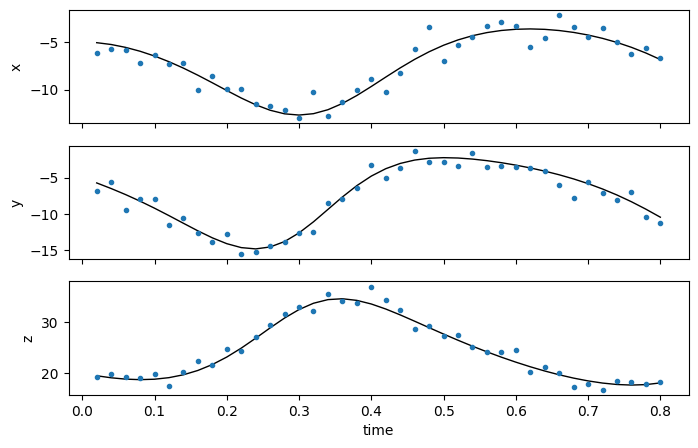

In [2]:
dt = 0.02
T = 40
xdim = ydim = 3


class Lorenz63(torch.nn.Module):
    def __init__(self, theta):
        super().__init__()
        self.theta = theta

    def update(self, params):
        if params is not None:
            self.theta = params

    def vector_field(self, x):
        sigma, rho, beta = self.theta
        return torch.stack([
            sigma * (x[..., 1] - x[..., 0]),
            x[..., 0] * (rho - x[..., 2]) - x[..., 1],
            x[..., 0] * x[..., 1] - beta * x[..., 2],
        ], dim=-1)

    def forward(self, x, u=None):
        k1 = self.vector_field(x)
        k2 = self.vector_field(x + dt / 2 * k1)
        k3 = self.vector_field(x + dt / 2 * k2)
        k4 = self.vector_field(x + dt * k3)
        return x + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)


def make_ssm(theta):
    dynamics = bside.NonlinearAdditiveModel(
        f=Lorenz63(theta), noise_cov=1e-2 * torch.eye(xdim), in_dim=xdim, out_dim=xdim,
    )
    observations = bside.LinearGaussianModel(
        model=bside.IdentityModel(xdim), noise_cov=torch.eye(ydim),
    )
    return bside.SSM(xdim=xdim, ydim=ydim, dynamics=dynamics, observations=observations)


theta_true = torch.tensor([10.0, 28.0, 8.0 / 3.0])
true_ssm = make_ssm(theta_true)

x0 = torch.tensor([-5.0, -5.0, 20.0])
x_true, y = true_ssm.measure(x=x0, T=T, return_x=True)
data = bside.Data(y=y)
init_dist = bside.FilteringDistribution(mean=x0, cov=torch.eye(xdim))

t = torch.arange(1, T + 1) * dt
fig, axes = plt.subplots(3, 1, figsize=(8, 5), sharex=True)
for i, (ax, name) in enumerate(zip(axes, 'xyz')):
    ax.plot(t, x_true[:, i], 'k', lw=1)
    ax.plot(t, y[:, i], '.', color='C0')
    ax.set_ylabel(name)
axes[-1].set_xlabel('time')
plt.show()

## Likelihood from two filters

Profile $\log p(y \mid \theta)$ over $\rho$, with $\sigma$ and $\beta$ held at
their true values. The UKF curve is smooth. The particle filter's estimates
scatter around it.

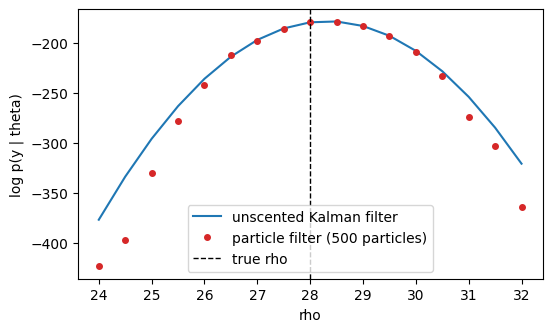

In [3]:
model = make_ssm(theta_true.clone())
ukf = bside.UnscentedKalmanFilter(model)
pf = bside.ParticleFilter(model, n_particles=500)

rhos = torch.linspace(24.0, 32.0, 17)
ll_ukf, ll_pf = [], []
with torch.no_grad():
    for rho in rhos:
        theta = torch.tensor([10.0, rho, 8.0 / 3.0])
        ll_ukf.append(-ukf.nlog_marginal_likelihood(data, init_dist, params=theta))
        ll_pf.append(-pf.nlog_marginal_likelihood(data, init_dist, params=theta))

plt.figure(figsize=(6, 3.5))
plt.plot(rhos, ll_ukf, 'C0-', label='unscented Kalman filter')
plt.plot(rhos, ll_pf, 'C3o', ms=4, label='particle filter (500 particles)')
plt.axvline(theta_true[1], color='k', ls='--', lw=1, label='true rho')
plt.xlabel('rho')
plt.ylabel('log p(y | theta)')
plt.legend()
plt.show()

## Posterior sampling with DRAM

The prior is uniform on $(0, 50)^3$. `Posterior` returns $-\infty$ outside the
prior's support without running the filter.

In [4]:
def log_prior(theta):
    inside = bool(((theta > 0) & (theta < 50)).all())
    return torch.tensor(0.0 if inside else float('-inf'))


posterior = bside.Posterior(filter=ukf, data=data, init_dist=init_dist, prior=log_prior)

dram = DelayedRejectionAdaptiveMetropolis(
    target=posterior,
    x0=torch.tensor([8.0, 25.0, 2.0]),
    cov=0.1 * torch.eye(3),
)
with torch.no_grad():
    samples, log_probs = dram(2000)
samples = samples[500:]  # discard burn-in

print(f'acceptance rate: {100 * dram.acceptance_ratio:.1f}%')
for name, true, mean, std in zip(['sigma', 'rho', 'beta'], theta_true, samples.mean(0), samples.std(0)):
    print(f'{name:>5}: true {true:6.3f}   posterior {mean:6.3f} +/- {std:.3f}')

acceptance rate: 79.1%
sigma: true 10.000   posterior  9.816 +/- 0.652
  rho: true 28.000   posterior 28.296 +/- 0.197
 beta: true  2.667   posterior  2.684 +/- 0.066


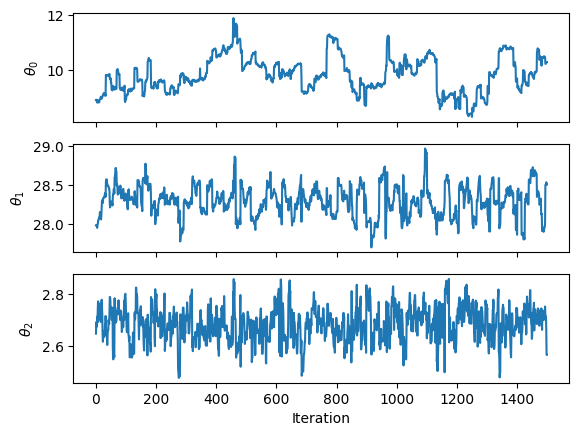

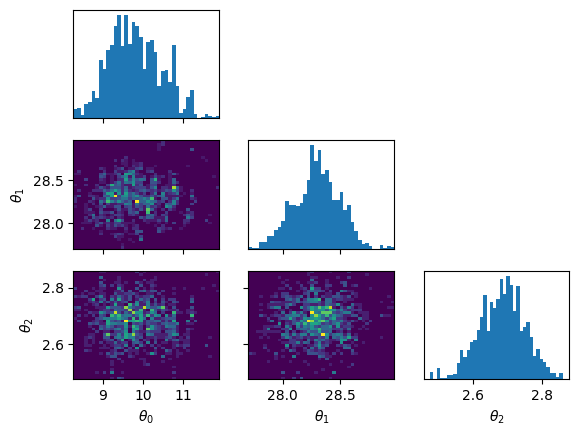

In [5]:
visualizer = SampleVisualizer(samples)
visualizer.chains()
visualizer.triangular_hist(bins=40)
plt.show()